# Практичне завдання 3: ефективність TF-IDF зважених ембедингів для детекції текстів, згенерованих LLM

**Задача:** бінарна класифікація текстів **Human** vs **AI**.
**Подання тексту:** субслівні ембединги **FastText** → вектор документа (Mean Pooling або TF-IDF Weighted Mean).
**Класифікатори:** SVM (RBF), Logistic Regression, KNN.
**Метрики:** macro-F1, Accuracy, Balanced Accuracy, ROC-AUC.

**План**
1. Завантаження та первинний аналіз даних (EDA, артефакти)
2. Попередня обробка тексту (spaCy) та розбиття train/test
3. Навчання FastText
4. Векторизація документів (Mean Pooling та TF-IDF Weighted Mean)
5. Навчання та оцінка класифікаторів (+ довірчі інтервали)
6. Візуалізація (t-SNE), матриці плутанини, геометричний аналіз
7. Лінгвістична інтерпретація (які слова/н-грами характерні для AI)
8. Відповіді на дослідницькі питання, загальний висновок

> **Встановлення залежностей** (один раз): `pip install spacy gensim scikit-learn pandas matplotlib scipy` та `python -m spacy download en_core_web_sm`.
>
> **Версія Python:** gensim та spaCy працюють не з усіма версіями Python. Використовуйте **Python 3.10–3.13** (на Python 3.14 gensim може не встановитись) або Google Colab, де все працює «з коробки».

In [11]:
import os, re, glob, time, pickle, hashlib, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from gensim.models import FastText
from scipy.spatial.distance import pdist, squareform
from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score,
                             confusion_matrix, silhouette_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150); pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (8, 4.5)
SEED = 42
np.random.seed(SEED)

## Теоретичні відомості (коротко, на інтуїції)

**FastText.** Слово розкладається на символьні n-грами (наприклад, для `generate` і n=3: `<ge, gen, ene, ner, era, rat, ate, te>` плюс саме слово `<generate>`). Вектор слова = **сума векторів його n-грам**: v_w = Σ_{g∈G(w)} z_g. Тому навіть слово, якого не було в корпусі (OOV, наприклад, друкарська помилка), отримує вектор — через спільні n-грами з відомими словами.

**TF-IDF.** TF-IDF(t,d,D) = tf(t,d)·idf(t,D), де tf — частота терміна в документі, а idf = log(|D| / df(t)) — «рідкісність» терміна в корпусі (df — кількість документів із цим терміном). Слова, що трапляються майже в кожному документі, мають idf ≈ 0, а рідкісні — великий idf.

**Агрегація вектора документа** з векторів слів w₁…w_m:
* **Mean Pooling:** v = (1/m) Σ v_{wᵢ} — усі слова мають однакову вагу;
* **TF-IDF Weighted Mean:** v = Σ tfidf(wᵢ)·v_{wᵢ} / Σ tfidf(wᵢ) — рідкісні (інформативні) слова впливають сильніше, загальновживані — слабше.

**Дослідницька гіпотеза:** LLM зберігають тематичну відповідність, але залишають статистичні «відбитки» у лексиці (канцеляризми, складні сполучники, характерні вставні конструкції). TF-IDF підсилює рідкісні, специфічні для AI терміни, що має покращити лінійну роздільність класів порівняно з Mean Pooling, де домінують часті спільні слова.

## Етап 1. Завантаження та первинний аналіз даних

### 1.1 Параметри та завантаження
Файл датасету (CSV з колонкою тексту та колонкою мітки, наприклад, *AI vs Human Text Classification Dataset* з Kaggle) має лежати поруч із ноутбуком (або в `data/`). Назви колонок **визначаються автоматично** (колонка тексту — найдовший рядковий стовпець; колонка мітки — стовпець із двома значеннями). За потреби їх можна задати вручну в параметрах нижче.

`MAX_DOCS` обмежує кількість документів (стратифікована вибірка зберігає пропорції класів): SVM з RBF-ядром та `probability=True` має складність, що росте приблизно квадратично з розміром вибірки. Поставте `None`, щоб використати весь датасет.

In [12]:
# ===== ПАРАМЕТРИ =====
DATA_PATH = "/content/ai_vs_human_text_2026.csv"      # шлях до файлу, напр. "data/ai_vs_human.csv"; None -> автопошук
TEXT_COL  = None      # назва колонки з текстом; None -> автовизначення
LABEL_COL = None      # назва колонки з міткою; None -> автовизначення
AI_LABEL  = None      # значення мітки, що означає "AI"; None -> автовизначення
MAX_DOCS  = 10000     # макс. кількість документів (None = усі)
MIN_WORDS = 5         # тексти коротші за стільки слів вважаємо артефактом

In [13]:
def read_any(p):
    pl = p.lower()
    if pl.endswith(".csv"): return pd.read_csv(p)
    if pl.endswith(".parquet"): return pd.read_parquet(p)
    return pd.read_excel(p)

def find_dataset():
    if DATA_PATH: return DATA_PATH
    cands = []
    for pat in ["*.csv", "data/*.csv", "/content/*.csv", "*.parquet", "data/*.parquet"]:
        cands += glob.glob(pat)
    cands = [c for c in cands if not os.path.basename(c).startswith(("tokens_cache", "results_"))]
    if not cands:
        raise FileNotFoundError("CSV-файл не знайдено. Завантажте датасет з Kaggle, покладіть поруч із ноутбуком "
                                "або вкажіть DATA_PATH у параметрах.")
    cands.sort(key=lambda p: (not re.search(r"ai|human|text", os.path.basename(p), re.I), -os.path.getsize(p)))
    return cands[0]

path = find_dataset()
raw = read_any(path)
print("Файл:", path, "| розмір:", raw.shape)
print("Колонки:", list(raw.columns))
raw.head(3)

Файл: /content/ai_vs_human_text_2026.csv | розмір: (2000, 9)
Колонки: ['text_id', 'label', 'source_model', 'domain', 'text_content', 'topic_hint', 'word_count', 'avg_sentence_length', 'generation_method']


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. th...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's complicated and anyone telling you otherwise is selling something. do yo...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,"Analysts are closely watching developments related to climate change adaptation strategies, noting that recent event...",climate change adaptation strategies,39,13.0,style_simulation


In [14]:
def detect_columns(df):
    obj = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c])]
    if not obj: raise ValueError("Не знайдено текстових колонок")
    text_col = TEXT_COL or max(obj, key=lambda c: df[c].astype(str).str.len().mean())
    cand = [c for c in df.columns if c != text_col and df[c].nunique(dropna=True) == 2]
    if not (LABEL_COL or cand): raise ValueError("Не знайдено колонку мітки з двома класами; задайте LABEL_COL")
    pref = [c for c in cand if re.search(r"label|class|generat|source|target|author|\bai\b|human", str(c), re.I)]
    label_col = LABEL_COL or (pref or cand)[0]
    return text_col, label_col

def to_binary(s):
    # повертає 1 для AI, 0 для Human
    if AI_LABEL is not None: return (s == AI_LABEL).astype(int)
    if not pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
        t = s.astype(str).str.lower()
        is_ai = t.str.contains(r"\bai\b|gpt|llm|generat|machine|bot|gemini|claude|synthetic", regex=True) & ~t.str.contains("human")
        return is_ai.astype(int)
    return (s == sorted(s.dropna().unique())[-1]).astype(int)     # числові мітки: більше значення = AI (напр. 1)

text_col, label_col = detect_columns(raw)
df = pd.DataFrame({"text": raw[text_col], "label": to_binary(raw[label_col]), "raw_label": raw[label_col]})
print(f"Колонка тексту: {text_col!r} | колонка мітки: {label_col!r}")
print("Відповідність значень мітки класам (1 = AI):")
display(df.groupby("raw_label")["label"].agg(["first", "size"]).rename(columns={"first": "клас (1=AI)", "size": "кількість"}))

Колонка тексту: 'text_content' | колонка мітки: 'label'
Відповідність значень мітки класам (1 = AI):


,клас (1=AI),кількість
raw_label,,
ai,1,666
human,0,1334


> Перевірте таблицю відповідності вище: значення, що означають згенеровані тексти, мають отримати клас **1 (AI)**. Якщо це не так, задайте `AI_LABEL` у параметрах.

### 1.2 Баланс класів та довжини текстів

Пропуски у тексті/мітці: 0 / 0


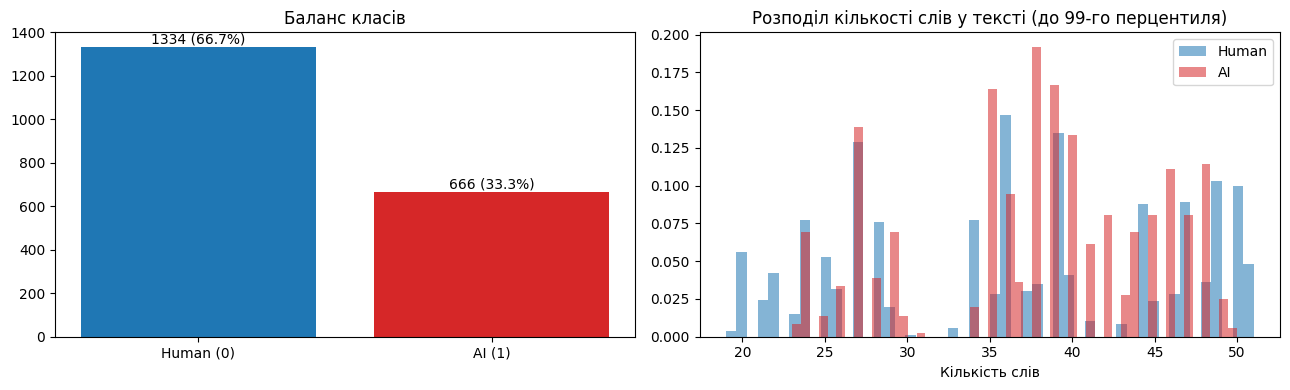

label               0      1
n_words count  1334.0  666.0
        mean     36.5   38.0
        std       9.7    7.0
        min      19.0   23.0
        25%      27.0   35.0
        50%      36.0   39.0
        75%      46.0   44.0
        max      52.0   50.0
n_chars count  1334.0  666.0
        mean    252.7  275.6
        std      88.3   71.1
        min     123.0  152.0
        25%     153.0  204.0
        50%     253.0  295.0
        75%     330.0  334.0
        max     398.0  385.0

In [15]:
df["text"] = df["text"].fillna("").astype(str)          # пропуски в тексті -> порожній рядок (далі видаляються як артефакт)
df["n_words"] = df["text"].str.split().str.len()
df["n_chars"] = df["text"].str.len()
print("Пропуски у тексті/мітці:", int(raw[text_col].isna().sum()), "/", int(raw[label_col].isna().sum()))

cnt = df["label"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(["Human (0)", "AI (1)"], [cnt.get(0, 0), cnt.get(1, 0)], color=["tab:blue", "tab:red"])
for i, v in enumerate([cnt.get(0, 0), cnt.get(1, 0)]): ax[0].text(i, v, f"{v} ({v/len(df):.1%})", ha="center", va="bottom")
ax[0].set_title("Баланс класів")
hi = df["n_words"].quantile(0.99)
for lab, col, name in [(0, "tab:blue", "Human"), (1, "tab:red", "AI")]:
    ax[1].hist(df.loc[df.label == lab, "n_words"].clip(upper=hi), bins=50, alpha=.55, color=col, label=name, density=True)
ax[1].set_title("Розподіл кількості слів у тексті (до 99-го перцентиля)"); ax[1].set_xlabel("Кількість слів"); ax[1].legend()
plt.tight_layout(); plt.show()
display(df.groupby("label")[["n_words", "n_chars"]].describe().T.round(1))

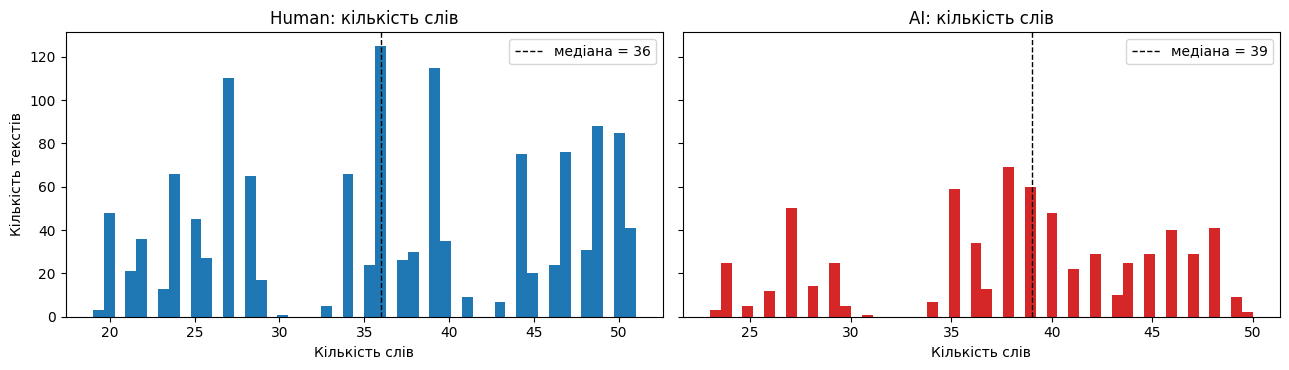

In [16]:
# Окремі гістограми кількості слів для кожного класу (за вимогою завдання)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, (lab, col, name) in zip(ax, [(0, "tab:blue", "Human"), (1, "tab:red", "AI")]):
    x = df.loc[df.label == lab, "n_words"]
    a.hist(x.clip(upper=hi), bins=50, color=col); a.axvline(x.median(), color="k", ls="--", lw=1, label=f"медіана = {x.median():.0f}")
    a.set_title(f"{name}: кількість слів"); a.set_xlabel("Кількість слів"); a.legend()
ax[0].set_ylabel("Кількість текстів"); plt.tight_layout(); plt.show()

### 1.3 Пошук артефактів: порожні рядки, надто короткі тексти, дублікати

In [17]:
empty = df["text"].str.strip().eq("") | df["text"].str.lower().isin(["nan", "none"])
short = (df["n_words"] < MIN_WORDS) & ~empty
dup_any = df.duplicated(subset="text", keep=False) & ~empty
conf = df[dup_any].groupby("text")["label"].nunique().gt(1)
n_conflict_texts = int(conf.sum())
print(f"Порожні / «nan» тексти:            {int(empty.sum())}")
print(f"Надто короткі (< {MIN_WORDS} слів):          {int(short.sum())}")
print(f"Рядків у групах дублікатів:        {int(dup_any.sum())} (унікальних текстів із дублями: {int(df[dup_any]['text'].nunique())})")
print(f"Дублікати з КОНФЛІКТНИМИ мітками:  {n_conflict_texts} текстів")
print("\nМожливий артефакт «довжина»: чи відрізняються класи за довжиною?")
from sklearn.model_selection import cross_val_score
Xlen = np.log1p(df[["n_words", "n_chars"]].values)
auc_len = cross_val_score(LogisticRegression(max_iter=1000), Xlen, df["label"], cv=5, scoring="roc_auc").mean()
print(f"ROC-AUC класифікатора, що бачить ЛИШЕ довжину тексту (5-fold): {auc_len:.3f}  (0.5 = довжина нічого не каже)")

Порожні / «nan» тексти:            0
Надто короткі (< 5 слів):          0
Рядків у групах дублікатів:        1567 (унікальних текстів із дублями: 533)
Дублікати з КОНФЛІКТНИМИ мітками:  0 текстів

Можливий артефакт «довжина»: чи відрізняються класи за довжиною?
ROC-AUC класифікатора, що бачить ЛИШЕ довжину тексту (5-fold): 0.631  (0.5 = довжина нічого не каже)


In [18]:
n0 = len(df)
bad_conflict = df["text"].isin(conf[conf].index)
df = df[~empty & ~short & ~bad_conflict].drop_duplicates(subset="text", keep="first").reset_index(drop=True)
print(f"Видалено: порожніх {int(empty.sum())}, коротких {int(short.sum())}, конфліктних дублікатів {int(bad_conflict.sum())}, "
      f"решта дублікатів — за drop_duplicates. Було {n0}, стало {len(df)}.")
if MAX_DOCS and len(df) > MAX_DOCS:
    df, _ = train_test_split(df, train_size=MAX_DOCS, stratify=df["label"], random_state=SEED)
    df = df.reset_index(drop=True)
    print(f"Стратифікована вибірка: {len(df)} документів (пропорції класів збережено)")
print("Баланс класів:", df["label"].value_counts().sort_index().to_dict())

Видалено: порожніх 0, коротких 0, конфліктних дублікатів 0, решта дублікатів — за drop_duplicates. Було 2000, стало 966.
Баланс класів: {0: 579, 1: 387}


**Висновок до EDA.** Таблиці та гістограми показують баланс класів, розподіл довжин та кількість артефактів. Артефакти видаляємо: порожні та надто короткі тексти (з них не побудувати змістовний вектор), дублікати (однакові тексти в train і test дають витік і завищують метрики) та конфліктні дублікати (той самий текст із різними мітками — шум розмітки). Окремо перевірено «артефакт довжини»: якщо ROC-AUC лише за довжиною помітно вищий за 0.5, класи відрізняються довжиною, і частину якості класифікаторів може пояснювати не лексика, а розмір тексту (на це слід зважати в інтерпретації результатів).

## Етап 2. Попередня обробка тексту (spaCy)

Пайплайн за методичкою: **лематизація**, **видалення стоп-слів**, **видалення небуквених токенів** (`is_alpha`), **нижній регістр**. Для швидкості використовуємо `nlp.pipe()` із батчами та вимикаємо непотрібні компоненти (`parser`, `ner`): для лем потрібні лише `tagger` та `attribute_ruler`.

In [19]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
nlp.max_length = 5_000_000

def preprocess(text: str) -> list:
    # еталонна версія з методички (по одному тексту)
    doc = nlp(text)
    tokens = []
    for token in doc:
        if token.is_alpha and not token.is_stop:
            tokens.append(token.lemma_.lower())
    return tokens

def preprocess_many(texts, batch_size=256, n_process=1):
    # те саме, але пакетно через nlp.pipe (швидше)
    return [[t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
            for doc in nlp.pipe(texts, batch_size=batch_size, n_process=n_process)]

demo = df["text"].iloc[0][:300]
print("Оригінал:", demo)
print("Після обробки:", preprocess(demo))
assert preprocess_many([demo])[0] == preprocess(demo), "пакетна версія має давати той самий результат"

Оригінал: can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize
Після обробки: ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']


In [20]:
key = hashlib.md5(("".join(df["text"].tolist()) + str(len(df))).encode()).hexdigest()[:10]
cache = f"tokens_cache_{key}.pkl"
if os.path.exists(cache):
    tokens_all = pickle.load(open(cache, "rb")); print("Токени завантажено з кешу:", cache)
else:
    t0 = time.time(); tokens_all = preprocess_many(df["text"].tolist(), batch_size=256)
    pickle.dump(tokens_all, open(cache, "wb")); print(f"Оброблено {len(tokens_all)} текстів за {time.time()-t0:.0f} с (збережено в {cache})")

df["tokens"] = tokens_all
df["n_tokens"] = df["tokens"].str.len()
df = df[df["n_tokens"] >= 3].reset_index(drop=True)          # документи, що стали порожніми після обробки

# Дублікати на рівні лем: тексти, що відрізняються лише стоп-словами, пунктуацією чи регістром, дають ОДНАКОВІ токени
# (а отже й однакові вектори). Якщо такі пари потраплять у train і test, це витік даних.
sig = df["tokens"].apply(" ".join)
conf_tok = df.groupby(sig)["label"].transform("nunique") > 1
n_dup_tok, n_conf_tok = int(sig.duplicated().sum()), int(conf_tok.sum())
df = df[~sig.duplicated(keep="first") & ~conf_tok].reset_index(drop=True)
print(f"Дублікатів на рівні лем видалено: {n_dup_tok} (конфліктних за міткою: {n_conf_tok})")
print("Документів після обробки:", len(df), "| середня кількість токенів:", round(df.n_tokens.mean(), 1))
display(df.groupby("label")["n_tokens"].describe().round(1))

Оброблено 966 текстів за 2 с (збережено в tokens_cache_ed0ee2cb1d.pkl)
Дублікатів на рівні лем видалено: 98 (конфліктних за міткою: 0)
Документів після обробки: 868 | середня кількість токенів: 21.5


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,481.0,20.0,7.4,7.0,12.0,21.0,25.0,33.0
1,387.0,23.2,7.6,10.0,15.0,26.0,30.0,33.0


### 2.1 Розбиття на train / test (до навчання FastText та IDF) — **за «родинами» майже-дублікатів**
Датасет створено за шаблонами, тому в ньому багато *майже-дублікатів* (тексти з однаковим каркасом, що відрізняються кількома словами). Звичайне випадкове розбиття кладе «родичів» і в train, і в test: тоді KNN просто знаходить у train двійника test-тексту й копіює його мітку (так ми й отримували F1 = 1.0 — це **витік даних**, а не якість методу).

Тому:
1. будуємо «родини» — зв'язні компоненти графа подібності (косинус TF-IDF ≥ `NEAR_DUP_THR`); **мітки при цьому не використовуються**;
2. розбиваємо **80/20 за родинами** (`StratifiedGroupKFold`): уся родина потрапляє або в train, або в test;
3. усе інше (FastText лише на train, IDF лише за train) лишається як було.

Звичайне випадкове розбиття зберігаємо лише як «оптимістичну» точку порівняння в Етапі 9.

In [21]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

NEAR_DUP_THR = 0.70       # поріг косинусної подібності для «родичів»; збільшіть, якщо утвориться одна гігантська родина
y = df["label"].values
N = len(df)

# 1) «родини» майже-дублікатів (лише тексти, без міток)
texts_all = [" ".join(t) for t in df["tokens"]]
T = TfidfVectorizer(sublinear_tf=True).fit_transform(texts_all)
rows_, cols_ = [], []
for s in range(0, N, 500):
    r, c = np.nonzero((T[s:s + 500] @ T.T).toarray() >= NEAR_DUP_THR); rows_.append(r + s); cols_.append(c)
r_all, c_all = np.concatenate(rows_), np.concatenate(cols_)
n_groups, groups = connected_components(csr_matrix((np.ones(len(r_all)), (r_all, c_all)), shape=(N, N)), directed=False)
sizes = np.bincount(groups)
print(f"Родин: {n_groups} із {N} документів | найбільша родина: {sizes.max()} ({sizes.max()/N:.1%}) | "
      f"документів у родинах розміру > 1: {(sizes[groups] > 1).mean():.1%}")
if sizes.max() / N > 0.5: print("УВАГА: одна родина охоплює > 50% даних — збільште NEAR_DUP_THR.")

# 2) ГОЛОВНЕ розбиття: за родинами (до навчання FastText та IDF)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_te = next(sgkf.split(np.zeros(N), y, groups))
assert not set(groups[idx_tr]) & set(groups[idx_te]), "жодна родина не має бути в обох множинах"

# звичайне випадкове розбиття — ТІЛЬКИ для порівняння в Етапі 9 (воно містить витік)
idx_tr_rand, idx_te_rand = train_test_split(np.arange(N), test_size=0.2, random_state=SEED, stratify=y)

tok_tr = [df["tokens"].iloc[i] for i in idx_tr]; tok_te = [df["tokens"].iloc[i] for i in idx_te]
y_train, y_test = y[idx_tr], y[idx_te]
print(f"Train: {len(idx_tr)} | Test: {len(idx_te)} | частка AI: train {y_train.mean():.3f}, test {y_test.mean():.3f}")

Родин: 63 із 868 документів | найбільша родина: 62 (7.1%) | документів у родинах розміру > 1: 96.7%
Train: 759 | Test: 109 | частка AI: train 0.481, test 0.202


## Етап 3. Навчання моделі FastText

Параметри за методичкою: `vector_size=100, window=5, min_count=2, sg=1` (skip-gram), `workers=4, seed=42`. Модель навчається на **train**-корпусі. Примітка: при `workers > 1` гарантувати побітову відтворюваність неможливо (порядок потоків), тому цифри можуть трохи відрізнятись між запусками.

In [22]:
t0 = time.time()
ft = FastText(sentences=tok_tr, vector_size=100, window=5, min_count=2, sg=1, workers=4, seed=42)
print(f"FastText навчено за {time.time()-t0:.0f} с | словник: {len(ft.wv.key_to_index)} слів | розмір вектора: {ft.vector_size}")

FastText навчено за 3 с | словник: 474 слів | розмір вектора: 100


In [23]:
# Ілюстрація формули (1): символьні n-грами слова
def char_ngrams(word, n=3):
    w = f"<{word}>"
    return sorted({w[i:i + n] for i in range(len(w) - n + 1)} | {w})
print("n-грами слова 'generate' (n=3):", char_ngrams("generate"))

# Вектор слова = сума векторів n-грам -> можна отримати вектор і для слова, якого не було в корпусі (OOV)
top_words = [w for w, _ in Counter(t for d in tok_tr for t in d).most_common(5)]
w0 = top_words[0]; typo = w0[:-1] + "x" if len(w0) > 3 else w0 + "x"
cos = lambda a, b: float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))
print(f"\nНайчастіші слова корпусу: {top_words}")
print(f"OOV-демо: слово {w0!r} є в словнику, а {typo!r} — {'є' if typo in ft.wv.key_to_index else 'немає'}, але вектор існує:")
print(f"  cos({w0}, {typo}) = {cos(ft.wv[w0], ft.wv[typo]):.3f}  |  cos({w0}, {top_words[1]}) = {cos(ft.wv[w0], ft.wv[top_words[1]]):.3f}")
for w in top_words[:3]:
    print(f"найближчі до {w!r}:", [(a, round(s, 2)) for a, s in ft.wv.most_similar(w, topn=5)])

n-грами слова 'generate' (n=3): ['<ge', '<generate>', 'ate', 'ene', 'era', 'gen', 'ner', 'rat', 'te>']

Найчастіші слова корпусу: ['challenge', 'official', 'need', 'come', 'long']
OOV-демо: слово 'challenge' є в словнику, а 'challengx' — немає, але вектор існує:
  cos(challenge, challengx) = 0.995  |  cos(challenge, official) = 0.795
найближчі до 'challenge': [('trend', 0.88), ('mental', 0.87), ('awareness', 0.87), ('recently', 0.87), ('highly', 0.87)]
найближчі до 'official': [('statement', 0.94), ('development', 0.92), ('release', 0.91), ('uncover', 0.91), ('formal', 0.9)]
найближчі до 'need': [('unhinged', 0.97), ('concerned', 0.96), ('tbh', 0.96), ('calm', 0.94), ('happy', 0.93)]


**Висновок.** FastText створює вектор для кожного слова з n-грам. Опечатка або рідкісна форма слова (OOV) отримує вектор, схожий на вектор «правильного» слова, бо вони мають багато спільних n-грам (cos помітно вищий, ніж між різними словами). Для задачі детекції AI-текстів це корисно: авторські/модельні «відбитки» часто проявляються в морфології та рідкісних формах, які звичайний Word2Vec відкинув би як невідомі слова.

## Етап 4. Векторизація документів

Для кожного документа (список лем) будуємо вектор двома способами:

* **Mean Pooling:** v = (1/m) Σ v_{wᵢ}
* **TF-IDF Weighted Mean:** v = Σ tfidf(wᵢ,d,D)·v_{wᵢ} / Σ tfidf(wᵢ,d,D)

**Реалізація TF-IDF за методичкою:** tf(t,d) = частота терміна в документі (кількість входжень / довжина документа), idf(t,D) = log(|D| / df(t)). Статистики df та |D| беруться **лише з train-документів**. Для термінів, яких немає в train-корпусі (трапляються лише в test), приймаємо df = 1, тобто вважаємо їх максимально рідкісними: idf = log|D|. Терміни, що є в **кожному** train-документі, мають idf = 0 і не впливають на вектор документа. Суми в формулі йдуть по **позиціях** токенів (як у методичці): слово, що повторюється, враховується кожного разу.

### Інтуїція на крихітному прикладі

In [24]:
class TfidfScorer:
    # tf = частота в документі, idf = log(N / df); fit лише на train-документах
    def fit(self, docs):
        self.N = len(docs); df_counter = Counter()
        for d in docs: df_counter.update(set(d))
        self.idf = {t: np.log(self.N / c) for t, c in df_counter.items()}
        self.idf_unseen = np.log(self.N)              # df=1 для термінів, яких не було в train
        return self
    def doc_scores(self, tokens):
        cnt, m = Counter(tokens), len(tokens)
        return {t: (c / m) * self.idf.get(t, self.idf_unseen) for t, c in cnt.items()}

# Приклад: 3 мініатюрні документи; слово 'cat' є в усіх, 'delve' і 'tapestry' — рідкісні
toy = [["cat", "sit", "mat"], ["cat", "eat", "fish"], ["delve", "tapestry", "cat"]]
sc = TfidfScorer().fit(toy)
print("idf:", {t: round(float(v), 3) for t, v in sc.idf.items()})
doc = toy[2]; scores = sc.doc_scores(doc); print("TF-IDF у документі 3:", {t: round(float(v), 3) for t, v in scores.items()})
emb = {"cat": np.array([1.0, 0.0]), "delve": np.array([0.0, 1.0]), "tapestry": np.array([0.2, 1.0])}   # умовні 2D-вектори
V = np.array([emb[t] for t in doc]); w = np.array([scores[t] for t in doc])
print("Mean Pooling      :", V.mean(0).round(3), "(слово 'cat' має вагу 1/3)")
print("TF-IDF Weighted   :", ((w[:, None] * V).sum(0) / w.sum()).round(3), "('cat' має вагу 0 — повністю ігнорується)")

idf: {'sit': 1.099, 'mat': 1.099, 'cat': 0.0, 'fish': 1.099, 'eat': 1.099, 'tapestry': 1.099, 'delve': 1.099}
TF-IDF у документі 3: {'delve': 0.366, 'tapestry': 0.366, 'cat': 0.0}
Mean Pooling      : [0.4   0.667] (слово 'cat' має вагу 1/3)
TF-IDF Weighted   : [0.1 1. ] ('cat' має вагу 0 — повністю ігнорується)


У цьому прикладі загальновживане слово `cat` (є в усіх документах) отримує нульову вагу, і вектор документа визначається рідкісними словами `delve`, `tapestry`. Саме це — механізм дослідницької гіпотези: слабка вага часто вживаним словам, велика — специфічним.

In [25]:
scorer = TfidfScorer().fit(tok_tr)
vec_cache = {}
def wv(t):
    v = vec_cache.get(t)
    if v is None:
        v = ft.wv[t]; vec_cache[t] = v          # для OOV вектор будується з n-грам
    return v

def mean_pooling(tokens):
    if not tokens: return np.zeros(ft.vector_size)
    return np.mean([wv(t) for t in tokens], axis=0)

def tfidf_weighted_pooling(tokens, scores):
    if not tokens: return np.zeros(ft.vector_size)
    w = np.array([scores[t] for t in tokens])
    if w.sum() <= 0: return mean_pooling(tokens)           # усі терміни мають idf=0
    V = np.array([wv(t) for t in tokens])
    return (w[:, None] * V).sum(0) / w.sum()

def featurize(token_lists):
    Xm = np.vstack([mean_pooling(t) for t in token_lists])
    Xt = np.vstack([tfidf_weighted_pooling(t, scorer.doc_scores(t)) for t in token_lists])
    return Xm, Xt

t0 = time.time()
Xtr_mean, Xtr_tf = featurize(tok_tr); Xte_mean, Xte_tf = featurize(tok_te)
print(f"Векторизація за {time.time()-t0:.0f} с | форма: train {Xtr_mean.shape}, test {Xte_mean.shape}")
for name, X in [("Mean (train)", Xtr_mean), ("TF-IDF (train)", Xtr_tf), ("Mean (test)", Xte_mean), ("TF-IDF (test)", Xte_tf)]:
    print(f"{name:15s} NaN: {int(np.isnan(X).sum())} | нульових векторів: {int((np.abs(X).sum(1) == 0).sum())}")
feats = {"Mean Pooling": (Xtr_mean, Xte_mean), "TF-IDF Weighted Mean": (Xtr_tf, Xte_tf)}

Векторизація за 0 с | форма: train (759, 100), test (109, 100)
Mean (train)    NaN: 0 | нульових векторів: 0
TF-IDF (train)  NaN: 0 | нульових векторів: 0
Mean (test)     NaN: 0 | нульових векторів: 0
TF-IDF (test)   NaN: 0 | нульових векторів: 0


## Етап 5. Навчання та оцінка класифікаторів

Для кожного методу агрегації навчаємо три класифікатори з параметрами методички: **SVM** (RBF, `probability=True`), **Logistic Regression** (`max_iter=1000`), **KNN** (k = 5). Оцінюємо на test: macro-F1, Accuracy, Balanced Accuracy, ROC-AUC (за ймовірністю класу AI).

Різниці між двома методами агрегації можуть бути невеликими, тому крім точкових значень рахуємо **95% довірчі інтервали різниці** (парний bootstrap по test-вибірці): якщо інтервал не містить 0, різниця статистично помітна.

In [26]:
classifiers = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "LogReg": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}
rows, store = [], {}
for agg, (Xa, Xb) in feats.items():
    for name, clf in classifiers.items():
        t0 = time.time(); m = clone(clf).fit(Xa, y_train); fit_t = time.time() - t0
        pred = m.predict(Xb); proba = m.predict_proba(Xb)[:, 1]
        store[(agg, name)] = {"pred": pred, "proba": proba}
        rows.append({"Агрегація": agg, "Класифікатор": name,
                     "F1 (macro)": f1_score(y_test, pred, average="macro"), "Accuracy": accuracy_score(y_test, pred),
                     "Balanced Acc": balanced_accuracy_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba),
                     "час навчання, с": fit_t})
        print(f"{agg:22s} {name:7s} F1={rows[-1]['F1 (macro)']:.4f}  ({fit_t:.0f} с)")
results = pd.DataFrame(rows)
display(results.set_index(["Агрегація", "Класифікатор"]).round(4))

Mean Pooling           SVM     F1=0.1679  (0 с)
Mean Pooling           LogReg  F1=0.3661  (0 с)
Mean Pooling           KNN     F1=0.4657  (0 с)
TF-IDF Weighted Mean   SVM     F1=0.1679  (0 с)
TF-IDF Weighted Mean   LogReg  F1=0.3266  (0 с)
TF-IDF Weighted Mean   KNN     F1=0.4657  (0 с)


F1 (macro)  Accuracy  Balanced Acc  ROC-AUC  час навчання, с
Агрегація            Класифікатор                                                              
Mean Pooling         SVM               0.1679    0.2018        0.5000   0.3333           0.1418
                     LogReg            0.3661    0.3670        0.6034   0.3229           0.0185
                     KNN               0.4657    0.4679        0.6667   0.6839           0.0019
TF-IDF Weighted Mean SVM               0.1679    0.2018        0.5000   0.3333           0.1288
                     LogReg            0.3266    0.3303        0.5805   0.3333           0.0273
                     KNN               0.4657    0.4679        0.6667   0.6724           0.0014

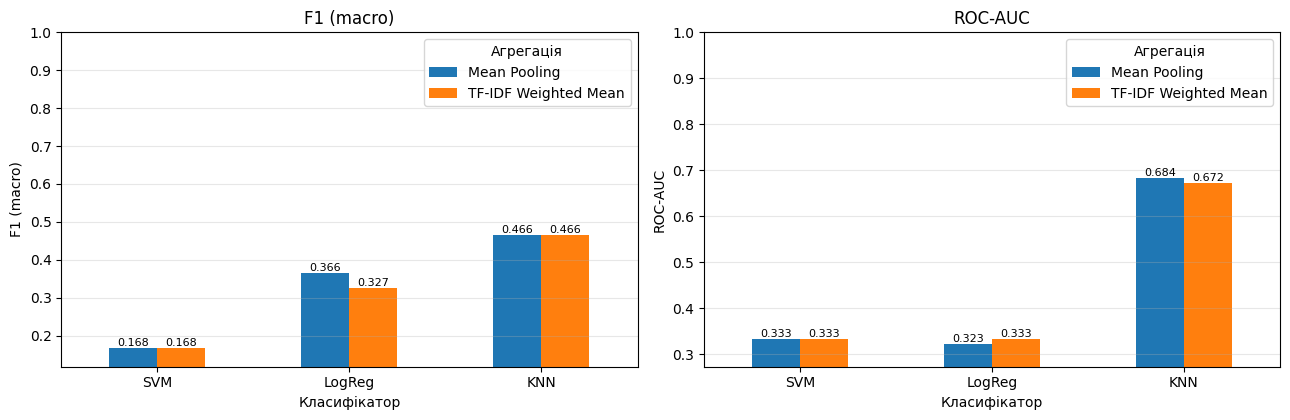

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a, metric in zip(ax, ["F1 (macro)", "ROC-AUC"]):
    pv = results.pivot(index="Класифікатор", columns="Агрегація", values=metric).loc[list(classifiers)]
    pv.plot.bar(ax=a, rot=0, color=["tab:blue", "tab:orange"]); a.set_title(metric); a.set_ylabel(metric)
    lo = max(0.0, float(pv.values.min()) - 0.05); a.set_ylim(lo, 1.0); a.grid(alpha=.3, axis="y")
    for p in a.patches: a.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

In [28]:
def paired_bootstrap(clf_name, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); n = len(y_test)
    a, b = store[("Mean Pooling", clf_name)], store[("TF-IDF Weighted Mean", clf_name)]
    d_f1, d_auc = [], []
    for _ in range(B):
        ix = rng.integers(0, n, n); yt = y_test[ix]
        d_f1.append(f1_score(yt, b["pred"][ix], average="macro") - f1_score(yt, a["pred"][ix], average="macro"))
        d_auc.append(roc_auc_score(yt, b["proba"][ix]) - roc_auc_score(yt, a["proba"][ix]))
    ci = lambda x: np.percentile(x, [2.5, 97.5])
    f1_obs = f1_score(y_test, b["pred"], average="macro") - f1_score(y_test, a["pred"], average="macro")
    auc_obs = roc_auc_score(y_test, b["proba"]) - roc_auc_score(y_test, a["proba"])
    return {"Класифікатор": clf_name, "ΔF1 (TF-IDF − Mean)": f1_obs, "ΔF1 95% CI": tuple(ci(d_f1).round(4)),
            "ΔAUC (TF-IDF − Mean)": auc_obs, "ΔAUC 95% CI": tuple(ci(d_auc).round(4))}
boot = pd.DataFrame([paired_bootstrap(n) for n in classifiers]).set_index("Класифікатор")
display(boot.round(4))

,ΔF1 (TF-IDF − Mean),ΔF1 95% CI,ΔAUC (TF-IDF − Mean),ΔAUC 95% CI
Класифікатор,,,,
SVM,0.0000,"(0.0, 0.0)",0.0000,"(0.0, 0.0)"
LogReg,-0.0395,"(-0.0802, -0.0089)",0.0104,"(0.0, 0.0275)"
KNN,0.0000,"(0.0, 0.0)",-0.0115,"(-0.0298, 0.0)"


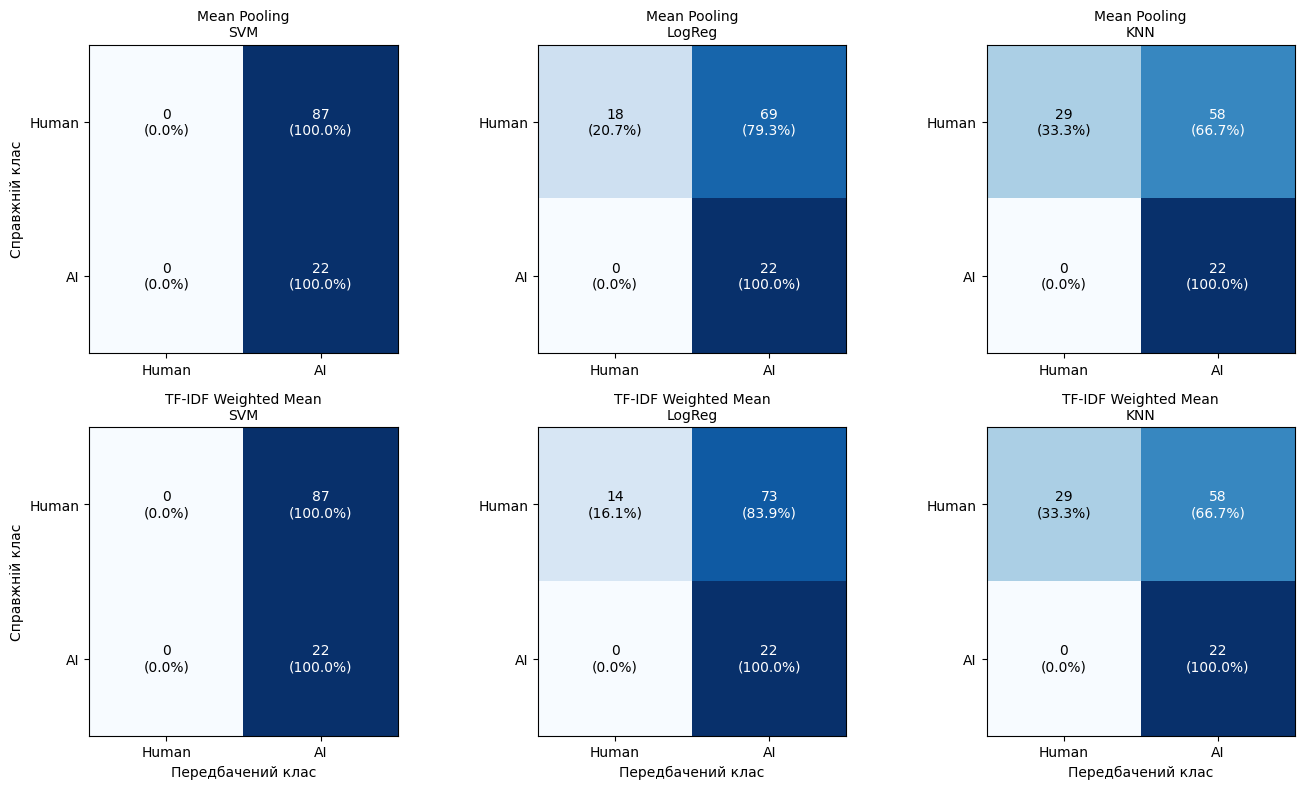

In [29]:
# Матриці плутанини: 2 агрегації × 3 класифікатори
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for i, agg in enumerate(feats):
    for j, name in enumerate(classifiers):
        cm = confusion_matrix(y_test, store[(agg, name)]["pred"]); cmn = cm / cm.sum(axis=1, keepdims=True)
        a = axes[i, j]; a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        for r in range(2):
            for c in range(2):
                a.text(c, r, f"{cm[r, c]}\n({cmn[r, c]:.1%})", ha="center", va="center", color="white" if cmn[r, c] > .5 else "black")
        a.set_xticks([0, 1]); a.set_xticklabels(["Human", "AI"]); a.set_yticks([0, 1]); a.set_yticklabels(["Human", "AI"])
        a.set_title(f"{agg}\n{name}", fontsize=10)
        if j == 0: a.set_ylabel("Справжній клас")
        if i == 1: a.set_xlabel("Передбачений клас")
plt.tight_layout(); plt.show()

### 5.1 Групова 5-fold крос-валідація — **основний результат**
Одне групове розбиття (Етап 2.1) дає нестабільну оцінку: родин лише ≈ 60, тому склад test (зокрема частка класу AI) сильно залежить від того, які родини в нього випали. Щоб результат не залежав від випадку, повторюємо **весь** експеримент (FastText на train → обидві агрегації → 3 класифікатори) на **5 фолдах `StratifiedGroupKFold`**: кожна родина рівно один раз потрапляє в test, і жодна ніколи не буває одночасно в train і test.

Показуємо: (1) чи «чисті» родини (усі документи одного класу) — це пояснює, чому шаблон=клас; (2) метрики по фолдах (середнє ± std); (3) метрики на об'єднаних out-of-fold прогнозах; (4) **кластерний bootstrap по родинах** для різниці TF-IDF − Mean (перевибираємо цілі родини, а не окремі документи, бо документи всередині родини не є незалежними).


Родин: 63 | «чистих» (усі документи одного класу): 63 (100%) | документів у чистих родинах: 100.0%
fold 1: train 759 / test 109 | родин у test: 12 | частка AI у test: 0.20
fold 2: train 679 / test 189 | родин у test: 15 | частка AI у test: 0.46
fold 3: train 608 / test 260 | родин у test: 15 | частка AI у test: 0.24
fold 4: train 658 / test 210 | родин у test: 14 | частка AI у test: 0.71
fold 5: train 768 / test 100 | родин у test: 7 | частка AI у test: 0.66

Метрики по фолдах: середнє та std


F1 (macro)         Balanced Acc         ROC-AUC        
                                        mean     std         mean     std    mean     std
Агрегація            Класифікатор                                                        
Mean Pooling         KNN              0.4696  0.1337       0.5695  0.1486  0.6222  0.2099
                     LogReg           0.3495  0.0903       0.5116  0.0553  0.4179  0.1872
                     SVM              0.3229  0.1406       0.5122  0.0172  0.4413  0.0936
TF-IDF Weighted Mean KNN              0.4743  0.0978       0.5862  0.1019  0.6682  0.1514
                     LogReg           0.3621  0.1043       0.5317  0.0321  0.4500  0.3044
                     SVM              0.3199  0.1359       0.5105  0.0138  0.4453  0.0929

Об'єднані out-of-fold прогнози (кожен документ оцінено моделлю, яка не бачила його родини):


F1 (macro)  Balanced Acc  ROC-AUC
Агрегація            Класифікатор                                   
Mean Pooling         SVM               0.3267        0.5083   0.5495
                     LogReg            0.3495        0.4919   0.3072
                     KNN               0.4826        0.5367   0.5766
TF-IDF Weighted Mean SVM               0.3244        0.5073   0.5735
                     LogReg            0.3662        0.5270   0.3811
                     KNN               0.4994        0.5548   0.6367

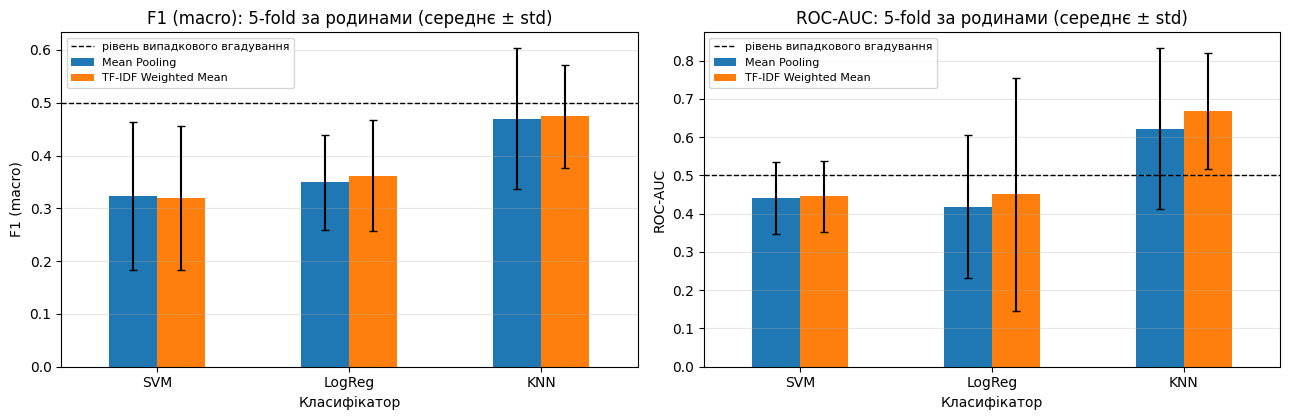

In [30]:
# ---- повний експеримент на одному розбитті: FastText (лише train) -> 2 агрегації -> 3 класифікатори ----
# (та сама функція використовується далі в Етапі 9 для порівняння з випадковим розбиттям)
def safe_auc(yt, p):
    return roc_auc_score(yt, p) if len(np.unique(yt)) > 1 else np.nan

def run_pipeline(i_tr, i_te, seed=SEED):
    tr = [df["tokens"].iloc[i] for i in i_tr]; te = [df["tokens"].iloc[i] for i in i_te]; ytr, yte = y[i_tr], y[i_te]
    ft_ = FastText(sentences=tr, vector_size=100, window=5, min_count=2, sg=1, workers=4, seed=seed)
    sc_ = TfidfScorer().fit(tr); cache = {}
    def emb(t):
        if t not in cache: cache[t] = ft_.wv[t]
        return cache[t]
    def feats_(tl):
        Xm, Xt = [], []
        for toks in tl:
            V = np.array([emb(t) for t in toks]); Xm.append(V.mean(0))
            s_ = sc_.doc_scores(toks); w = np.array([s_[t] for t in toks])
            Xt.append((w[:, None] * V).sum(0) / w.sum() if w.sum() > 0 else V.mean(0))
        return np.vstack(Xm), np.vstack(Xt)
    (Am, At), (Bm, Bt) = feats_(tr), feats_(te)
    rows_, st = [], {}
    for agg, (Xa, Xb) in {"Mean Pooling": (Am, Bm), "TF-IDF Weighted Mean": (At, Bt)}.items():
        for name, clf in classifiers.items():
            m = clone(clf).fit(Xa, ytr); pred = m.predict(Xb); proba = m.predict_proba(Xb)[:, 1]; st[(agg, name)] = {"pred": pred, "proba": proba}
            rows_.append({"Агрегація": agg, "Класифікатор": name, "F1 (macro)": f1_score(yte, pred, average="macro"),
                          "ROC-AUC": safe_auc(yte, proba), "Balanced Acc": balanced_accuracy_score(yte, pred)})
    return pd.DataFrame(rows_), st, yte

# ---- (1) чи «чисті» родини? ----
gdf = pd.DataFrame({"g": groups, "y": y}).groupby("g")["y"].agg(["size", "mean"])
pure = gdf["mean"].isin([0.0, 1.0])
print(f"Родин: {len(gdf)} | «чистих» (усі документи одного класу): {int(pure.sum())} ({pure.mean():.0%}) | "
      f"документів у чистих родинах: {gdf.loc[pure, 'size'].sum() / N:.1%}")

# ---- (2) 5-fold за родинами ----
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(N), y, groups))
keys = [(a, c) for a in ("Mean Pooling", "TF-IDF Weighted Mean") for c in classifiers]
oof_pred = {k: np.full(N, -1) for k in keys}; oof_proba = {k: np.full(N, np.nan) for k in keys}
tables = []
for f, (a_idx, b_idx) in enumerate(folds, 1):
    assert not set(groups[a_idx]) & set(groups[b_idx]), "родина потрапила і в train, і в test"
    res_f, st_f, yte_f = run_pipeline(a_idx, b_idx)
    for k in keys:
        oof_pred[k][b_idx] = st_f[k]["pred"]; oof_proba[k][b_idx] = st_f[k]["proba"]
    res_f["fold"] = f; tables.append(res_f)
    print(f"fold {f}: train {len(a_idx)} / test {len(b_idx)} | родин у test: {len(set(groups[b_idx]))} | частка AI у test: {yte_f.mean():.2f}")
cv_res = pd.concat(tables, ignore_index=True)

print("\nМетрики по фолдах: середнє та std")
summary = cv_res.groupby(["Агрегація", "Класифікатор"])[["F1 (macro)", "Balanced Acc", "ROC-AUC"]].agg(["mean", "std"])
display(summary.round(4))

# ---- (3) метрики на об'єднаних out-of-fold прогнозах ----
pooled = pd.DataFrame([{"Агрегація": a, "Класифікатор": c,
                        "F1 (macro)": f1_score(y, oof_pred[(a, c)], average="macro"),
                        "Balanced Acc": balanced_accuracy_score(y, oof_pred[(a, c)]),
                        "ROC-AUC": roc_auc_score(y, oof_proba[(a, c)])} for a, c in keys]).set_index(["Агрегація", "Класифікатор"])
print("Об'єднані out-of-fold прогнози (кожен документ оцінено моделлю, яка не бачила його родини):")
display(pooled.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a_, metric in zip(ax, ["F1 (macro)", "ROC-AUC"]):
    m_ = summary[metric]["mean"].unstack(0).loc[list(classifiers)]; s_ = summary[metric]["std"].unstack(0).loc[list(classifiers)]
    m_.plot.bar(ax=a_, yerr=s_, rot=0, capsize=3, color=["tab:blue", "tab:orange"]); a_.set_title(f"{metric}: 5-fold за родинами (середнє ± std)")
    a_.axhline(0.5, color="k", ls="--", lw=1, label="рівень випадкового вгадування"); a_.set_ylabel(metric); a_.grid(alpha=.3, axis="y"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()


In [31]:
# ---- (4) кластерний bootstrap по родинах: різниця TF-IDF − Mean на об'єднаних out-of-fold прогнозах ----
ug = np.unique(groups); members = {g: np.where(groups == g)[0] for g in ug}
def cluster_bootstrap(clf_name, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); A, Bk = ("Mean Pooling", clf_name), ("TF-IDF Weighted Mean", clf_name)
    d_f1, d_auc = [], []
    for _ in range(B):
        ix = np.concatenate([members[g] for g in rng.choice(ug, size=len(ug), replace=True)]); yt = y[ix]
        if len(np.unique(yt)) < 2: continue
        d_f1.append(f1_score(yt, oof_pred[Bk][ix], average="macro") - f1_score(yt, oof_pred[A][ix], average="macro"))
        d_auc.append(roc_auc_score(yt, oof_proba[Bk][ix]) - roc_auc_score(yt, oof_proba[A][ix]))
    ci = lambda x: tuple(np.percentile(x, [2.5, 97.5]).round(4))
    return {"Класифікатор": clf_name,
            "ΔF1 (TF-IDF − Mean)": f1_score(y, oof_pred[Bk], average="macro") - f1_score(y, oof_pred[A], average="macro"), "ΔF1 95% CI": ci(d_f1),
            "ΔAUC (TF-IDF − Mean)": roc_auc_score(y, oof_proba[Bk]) - roc_auc_score(y, oof_proba[A]), "ΔAUC 95% CI": ci(d_auc)}

boot_cv = pd.DataFrame([cluster_bootstrap(c) for c in classifiers]).set_index("Класифікатор")
display(boot_cv.round(4))
judge_cv = lambda lo, hi: "ПОКРАЩЕННЯ" if lo > 0 else ("ПОГІРШЕННЯ" if hi < 0 else "незначуща")
print("Вердикт (кластерний bootstrap, 95% CI):")
for clf, r in boot_cv.iterrows():
    print(f"  {clf:7s}: ΔF1 -> {judge_cv(*r['ΔF1 95% CI'])} | ΔAUC -> {judge_cv(*r['ΔAUC 95% CI'])}")


,ΔF1 (TF-IDF − Mean),ΔF1 95% CI,ΔAUC (TF-IDF − Mean),ΔAUC 95% CI
Класифікатор,,,,
SVM,-0.0023,"(-0.0082, 0.0)",0.0240,"(-0.0371, 0.0954)"
LogReg,0.0166,"(-0.0068, 0.0512)",0.0738,"(0.0077, 0.1512)"
KNN,0.0168,"(-0.0461, 0.1034)",0.0601,"(0.0044, 0.1333)"


Вердикт (кластерний bootstrap, 95% CI):
  SVM    : ΔF1 -> незначуща | ΔAUC -> незначуща
  LogReg : ΔF1 -> незначуща | ΔAUC -> ПОКРАЩЕННЯ
  KNN    : ΔF1 -> незначуща | ΔAUC -> ПОКРАЩЕННЯ


**Як читати 5.1.**
* **ROC-AUC ≈ 0.5** означає, що модель не відрізняє AI від людини краще за випадковість; **ROC-AUC < 0.5** — що на нових родинах вона систематично помиляється «в інший бік» (вивчила ознаки конкретних шаблонів, які для нових шаблонів не працюють). Це не помилка коду, а наслідок того, що в шаблонному датасеті мітка майже повністю визначається шаблоном (див. частку «чистих» родин вище): коли test містить лише *нові* шаблони, перенесення знань неможливе.
* **std по фолдах** показує, наскільки результат залежить від того, які родини потрапили в test. Якщо std порівняний із різницею між методами — різниця між Mean Pooling і TF-IDF Weighted Mean не підтверджена.
* **Кластерний bootstrap** чесніший за звичайний, бо перевибирає цілі родини. Якщо 95% CI містить 0 — ефекту TF-IDF-зважування немає.
* **Висновки для питань 1–3 слід формулювати за цією секцією** (5-fold за родинами), а не за результатами одного фолду (Етап 5) і не за випадковим розбиттям (Етап 9, оптимістична оцінка).


## Етап 6. Візуалізація та геометричний аналіз

### 6.1 t-SNE проекція документних векторів
Беремо випадкову підвибірку test-документів (до 3000) і проектуємо їх на 2D за допомогою t-SNE окремо для Mean Pooling і для TF-IDF Weighted Mean. Крім візуального враження рахуємо кількісні показники кластеризації: **silhouette** (у вихідному 100-вимірному просторі й у 2D) та **чистоту сусідів** (частка з 10 найближчих сусідів, що мають ту саму мітку).

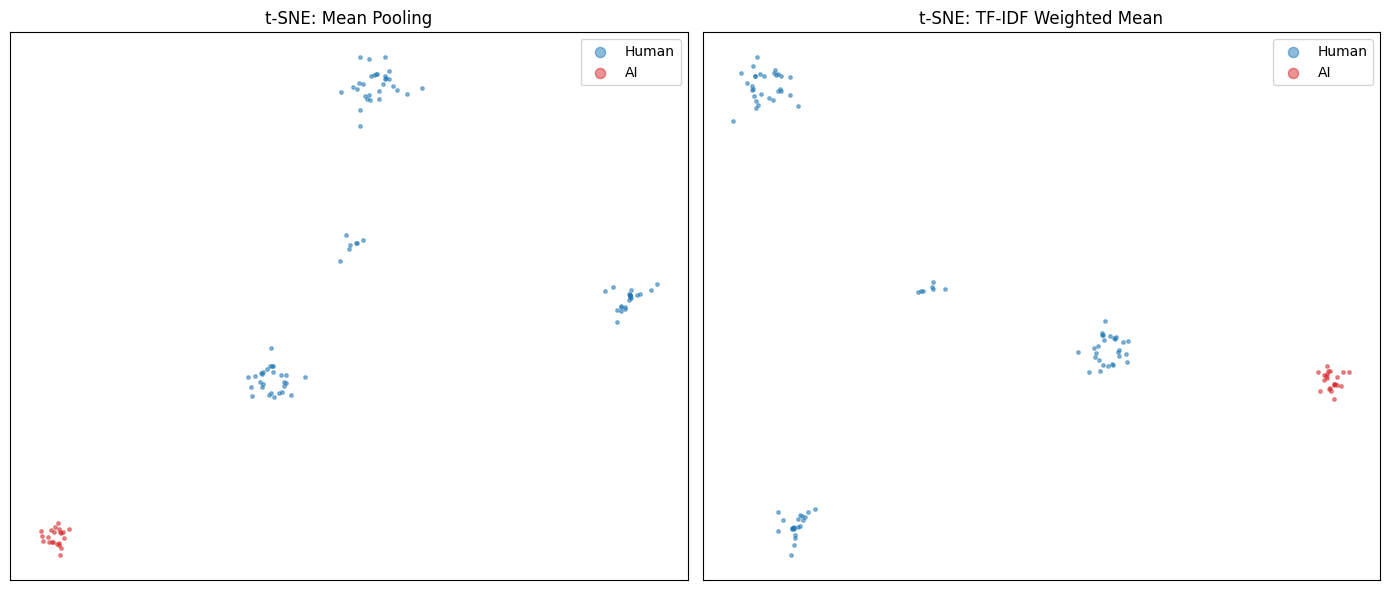

,silhouette (100-вимірний),silhouette (t-SNE 2D),чистота 10 сусідів
Агрегація,,,
Mean Pooling,0.3770,0.5571,1.0
TF-IDF Weighted Mean,0.3016,0.4531,1.0


In [32]:
rng = np.random.default_rng(SEED)
sel = rng.choice(len(y_test), size=min(3000, len(y_test)), replace=False)
ys = y_test[sel]; emb2d, quant = {}, []
for agg, (_, Xb) in feats.items():
    A = Xb[sel]
    Z = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(A)
    emb2d[agg] = Z
    nn = NearestNeighbors(n_neighbors=11).fit(A); ind = nn.kneighbors(A, return_distance=False)[:, 1:]
    purity = float((ys[ind] == ys[:, None]).mean())
    quant.append({"Агрегація": agg, "silhouette (100-вимірний)": silhouette_score(A, ys),
                  "silhouette (t-SNE 2D)": silhouette_score(Z, ys), "чистота 10 сусідів": purity})

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, agg in zip(ax, feats):
    Z = emb2d[agg]
    for lab, col, name in [(0, "tab:blue", "Human"), (1, "tab:red", "AI")]:
        a.scatter(Z[ys == lab, 0], Z[ys == lab, 1], s=6, alpha=.5, c=col, label=name)
    a.set_title(f"t-SNE: {agg}"); a.set_xticks([]); a.set_yticks([]); a.legend(markerscale=3)
plt.tight_layout(); plt.show()
display(pd.DataFrame(quant).set_index("Агрегація").round(4))

### 6.2 Геометрія векторних просторів
Щоб відповісти на питання про вплив TF-IDF на геометрію, порівняємо характеристики двох просторів (на підвибірці train-векторів):

| показник | що означає |
|---|---|
| середня норма | «розмір» векторів документів |
| середній cos між документами | наскільки документи «дивляться в один бік» (анізотропія); близько до 1 — усі документи в вузькому конусі |
| CV відстаней = σ/μ | розкид парних відстаней відносно середнього; малий CV означає «концентрацію відстаней» (прокляття розмірності) |
| відносний контраст RC = (d_max − d_min)/d_min | наскільки найближчий сусід відрізняється від найдальшого; RC → 0 означає, що «найближчий» майже не ближчий за «найдальший» |
| n₉₀, ефективна розмірність | скільки головних компонент потрібно для 90% дисперсії; скільки вимірів реально «працює» |
| роздільність центроїдів | відстань між центроїдами класів / внутрішньокласовий розкид |

In [33]:
def geometry(X, y_, n=2000, seed=SEED):
    rng = np.random.default_rng(seed); ix = rng.choice(len(X), min(n, len(X)), replace=False); A, yy = X[ix], y_[ix]
    norms = np.linalg.norm(A, axis=1)
    D = squareform(pdist(A)); iu = np.triu_indices_from(D, 1); d = D[iu]
    An = A / np.linalg.norm(A, axis=1, keepdims=True).clip(1e-12); mean_cos = float((An @ An.T)[iu].mean())
    Dpos = np.where(D > 0, D, np.inf); dmin = Dpos.min(axis=1); dmax = D.max(axis=1)     # найближчий сусід з ненульовою відстанню
    ok = np.isfinite(dmin); rc = float(((dmax[ok] - dmin[ok]) / dmin[ok]).mean())
    zero_frac = float((d == 0).mean())                                                     # частка пар з ідентичними векторами
    ev = PCA().fit(A).explained_variance_; evr = ev / ev.sum()
    n90 = int(np.searchsorted(np.cumsum(evr), 0.9) + 1); eff_dim = float(ev.sum() ** 2 / (ev ** 2).sum())
    mu0, mu1 = A[yy == 0].mean(0), A[yy == 1].mean(0)
    within = 0.5 * (A[yy == 0].var(0).sum() + A[yy == 1].var(0).sum())
    return {"середня норма": norms.mean(), "середній cos між документами": mean_cos, "CV відстаней (σ/μ)": float(d.std() / d.mean()),
            "відносний контраст RC": rc, "частка нульових відстаней": zero_frac, "n90 (PCA)": n90, "ефективна розмірність": eff_dim,
            "роздільність центроїдів": float(np.linalg.norm(mu1 - mu0) / np.sqrt(within)),
            "silhouette (100D)": float(silhouette_score(A, yy))}

geo = pd.DataFrame({agg: geometry(Xa, y_train) for agg, (Xa, _) in feats.items()})
display(geo.round(4))

,Mean Pooling,TF-IDF Weighted Mean
середня норма,2.0275,2.0112
середній cos між документами,0.7451,0.7471
CV відстаней (σ/μ),0.3305,0.3255
відносний контраст RC,47.2395,36.5397
частка нульових відстаней,0.0000,0.0000
n90 (PCA),8.0000,8.0000
ефективна розмірність,6.4048,6.7112
роздільність центроїдів,0.3760,0.3785
silhouette (100D),0.0694,0.0699


### 6.3 Чутливість KNN: кількість сусідів, розмірність і метрика
KNN — «ліниве» локальне правило: воно не навчається, які напрямки простору важливі, а покладається лише на відстані. Тому геометрія простору (концентрація відстаней, шум у непотрібних напрямках) впливає на нього сильніше, ніж на SVM чи LogReg. Перевіримо, як якість KNN залежить від k, від кількості вимірів (PCA) та від метрики.

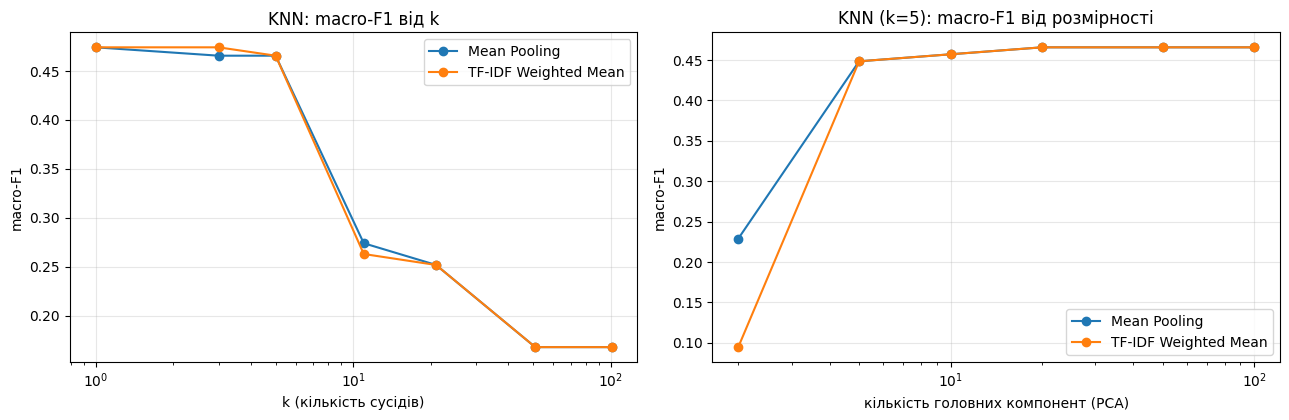

метрика,cosine,euclidean
Агрегація,,
Mean Pooling,0.4657,0.4657
TF-IDF Weighted Mean,0.4657,0.4657


In [34]:
ks = [1, 3, 5, 11, 21, 51, 101]; dims = [2, 5, 10, 20, 50, 100]
knn_k, knn_d, knn_metric = {}, {}, []
for agg, (Xa, Xb) in feats.items():
    knn_k[agg] = [f1_score(y_test, KNeighborsClassifier(n_neighbors=k).fit(Xa, y_train).predict(Xb), average="macro") for k in ks]
    out = []
    for dd in dims:
        p = PCA(n_components=dd, random_state=SEED).fit(Xa)
        out.append(f1_score(y_test, KNeighborsClassifier(n_neighbors=5).fit(p.transform(Xa), y_train).predict(p.transform(Xb)), average="macro"))
    knn_d[agg] = out
    for metric in ["euclidean", "cosine"]:
        pr = KNeighborsClassifier(n_neighbors=5, metric=metric, algorithm="brute").fit(Xa, y_train).predict(Xb)
        knn_metric.append({"Агрегація": agg, "метрика": metric, "F1 (macro), k=5": f1_score(y_test, pr, average="macro")})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for agg, col in zip(feats, ["tab:blue", "tab:orange"]):
    ax[0].plot(ks, knn_k[agg], "o-", label=agg, color=col); ax[1].plot(dims, knn_d[agg], "o-", label=agg, color=col)
ax[0].set_xscale("log"); ax[0].set_xlabel("k (кількість сусідів)"); ax[0].set_title("KNN: macro-F1 від k")
ax[1].set_xscale("log"); ax[1].set_xlabel("кількість головних компонент (PCA)"); ax[1].set_title("KNN (k=5): macro-F1 від розмірності")
for a in ax: a.set_ylabel("macro-F1"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(knn_metric).pivot(index="Агрегація", columns="метрика", values="F1 (macro), k=5").round(4))

## Етап 7. Лінгвістична інтерпретація: які слова та n-грами характерні для AI

Щоб відповісти на дослідницьке питання 4, рахуємо TF-IDF для слів і біграм (на train) та дивимось:
1. **різницю середніх TF-IDF** між класами (які терміни «вагоміші» в AI-текстах);
2. **коефіцієнти логістичної регресії** на розрідженому TF-IDF (які терміни найсильніше *розділяють* класи — вагомість сама по собі ще не означає розрізняльну силу);
3. те саме для **символьних n-грам** (3–5 символів), що відповідає ідеї FastText.

> Увага 1: аналіз проводиться за лемами після видалення стоп-слів та пунктуації, тому стилометричні ознаки на кшталт довжини речень, розділових знаків, службових слів тут не видно.
>
> Увага 2 (шаблонні артефакти): якщо датасет згенеровано за шаблонами (у вашому наборі `generation_method` = `template+human_variation` для людських текстів), то «маркери» можуть бути частинами самих шаблонів (наприклад, фрази-заготовки), а не справжньою стилістикою людей чи моделей. Такі терміни треба інтерпретувати обережно.

In [35]:
texts_tr = [" ".join(t) for t in tok_tr]; texts_te = [" ".join(t) for t in tok_te]
tv = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True).fit(texts_tr)
Mtr, Mte = tv.transform(texts_tr), tv.transform(texts_te); terms = np.array(tv.get_feature_names_out())
mean_ai = np.asarray(Mtr[y_train == 1].mean(0)).ravel(); mean_h = np.asarray(Mtr[y_train == 0].mean(0)).ravel()
lr_sparse = LogisticRegression(max_iter=2000, C=1.0, random_state=SEED).fit(Mtr, y_train)
coef = lr_sparse.coef_.ravel()
print(f"Довідково: LogReg на розрідженому word TF-IDF (1–2-грами) — test macro-F1 = "
      f"{f1_score(y_test, lr_sparse.predict(Mte), average='macro'):.4f} (не входить до основного порівняння)")

diff = mean_ai - mean_h
top_ai_mean = pd.DataFrame({"термін": terms[np.argsort(-diff)[:15]], "середній TF-IDF AI − Human": np.sort(diff)[::-1][:15]})
top_h_mean  = pd.DataFrame({"термін": terms[np.argsort(diff)[:15]], "середній TF-IDF AI − Human": np.sort(diff)[:15]})
top_ai_lr = pd.DataFrame({"термін": terms[np.argsort(-coef)[:15]], "коеф. LogReg": np.sort(coef)[::-1][:15]})
top_h_lr  = pd.DataFrame({"термін": terms[np.argsort(coef)[:15]], "коеф. LogReg": np.sort(coef)[:15]})
print("\nТермінів із найбільшою перевагою за середнім TF-IDF у класі AI:"); display(top_ai_mean.round(4))
print("Терміни, найсильніше розділяючі клас AI (коефіцієнти LogReg > 0):"); display(top_ai_lr.round(3))
print("Терміни, найсильніше розділяючі клас Human (коефіцієнти LogReg < 0):"); display(top_h_lr.round(3))

Довідково: LogReg на розрідженому word TF-IDF (1–2-грами) — test macro-F1 = 0.6849 (не входить до основного порівняння)

Термінів із найбільшою перевагою за середнім TF-IDF у класі AI:


,термін,середній TF-IDF AI − Human
0,think,0.0234
1,expert,0.0207
2,solution,0.0204
3,assumption,0.0193
4,open,0.0191
5,approach,0.0190
6,progress,0.0189
7,follow,0.0189
8,stakeholder,0.0189
9,potential,0.0187


Терміни, найсильніше розділяючі клас AI (коефіцієнти LogReg > 0):


,термін,коеф. LogReg
0,think,0.867
1,assumption,0.818
2,solution,0.811
3,progress,0.804
4,follow,0.804
5,approach,0.800
6,expert,0.792
7,potential,0.776
8,recommend,0.760
9,engage,0.758


Терміни, найсильніше розділяючі клас Human (коефіцієнти LogReg < 0):


,термін,коеф. LogReg
0,like,-1.105
1,get,-1.092
2,tell,-1.064
3,say,-0.933
4,argue,-0.906
5,update,-0.854
6,sell research,-0.854
7,sell,-0.854
8,complicated,-0.854
9,tell sell,-0.854


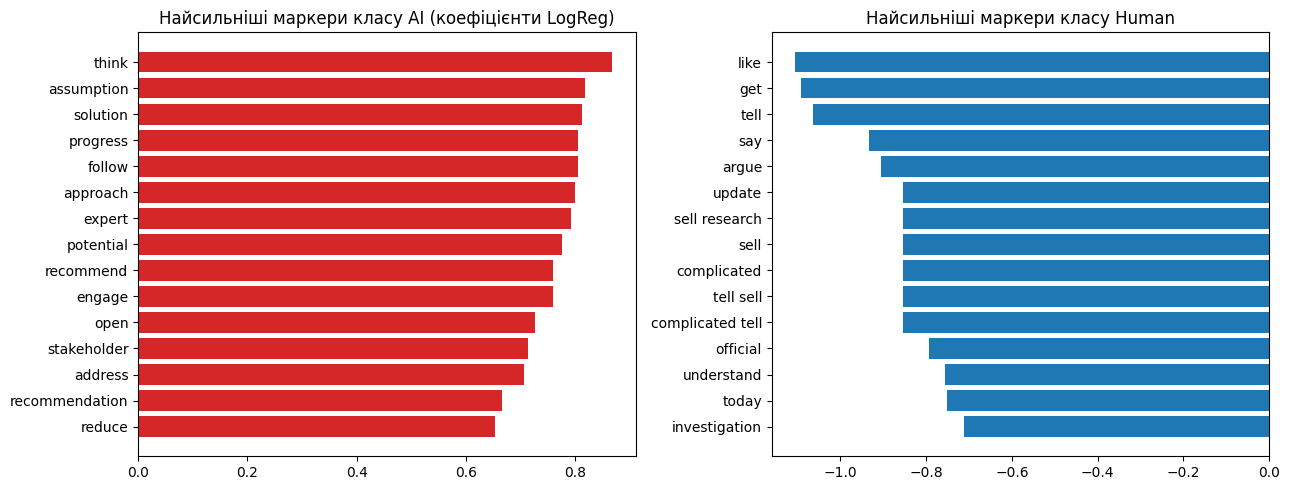

Довідково: LogReg на символьних n-грамах — test macro-F1 = 0.4657
Символьні n-грами, найхарактерніші для AI:    [' rec', 'rec', 'ina', 'end', ' reco', 'reco', 'pro', 'ge ', 'eco', 'thin', ' thin', ' thi', ' op', 'tin', 'ope', 'ake', 'ass', ' as', ' ass', ' fo']
Символьні n-грами, найхарактерніші для Human: ['ell ', 'ell', 'ay ', 'ed ', ' get', 'get', 'get ', ' get ', ' li', 'll ', 'time', ' tim', ' ti', ' time', ' lik', ' like', 'et ', 'ze ', 'lis', ' un']


In [36]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(top_ai_lr["термін"][::-1], top_ai_lr["коеф. LogReg"][::-1], color="tab:red"); ax[0].set_title("Найсильніші маркери класу AI (коефіцієнти LogReg)")
ax[1].barh(top_h_lr["термін"][::-1], top_h_lr["коеф. LogReg"][::-1], color="tab:blue"); ax[1].set_title("Найсильніші маркери класу Human")
plt.tight_layout(); plt.show()

# Символьні n-грами (ідея FastText)
cv = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=10, max_features=100000, sublinear_tf=True).fit(texts_tr)
Ctr = cv.transform(texts_tr); cterms = np.array(cv.get_feature_names_out())
lr_c = LogisticRegression(max_iter=2000, random_state=SEED).fit(Ctr, y_train); cc = lr_c.coef_.ravel()
print("Довідково: LogReg на символьних n-грамах — test macro-F1 =", round(f1_score(y_test, lr_c.predict(cv.transform(texts_te)), average="macro"), 4))
print("Символьні n-грами, найхарактерніші для AI:   ", list(cterms[np.argsort(-cc)[:20]]))
print("Символьні n-грами, найхарактерніші для Human:", list(cterms[np.argsort(cc)[:20]]))

## Етап 8. Відповіді на дослідницькі питання

Спочатку автоматично зведемо ключові числа (щоб відповіді спиралися саме на ваші результати).

In [37]:
print("===== 1) Вплив TF-IDF-агрегації на якість (TF-IDF − Mean), 95% bootstrap CI =====")
judge = lambda lo, hi: "ПОКРАЩЕННЯ" if lo > 0 else ("ПОГІРШЕННЯ" if hi < 0 else "незначуща")
for clf, r in boot.iterrows():
    lo, hi = r["ΔF1 95% CI"]; alo, ahi = r["ΔAUC 95% CI"]
    print(f"  {clf:7s}: ΔF1 = {r['ΔF1 (TF-IDF − Mean)']:+.4f} CI [{lo:+.4f}, {hi:+.4f}] -> {judge(lo, hi)} | "
          f"ΔAUC = {r['ΔAUC (TF-IDF − Mean)']:+.4f} CI [{alo:+.4f}, {ahi:+.4f}] -> {judge(alo, ahi)}")
if (results["F1 (macro)"] >= 0.995).any():
    print("  !!! УВАГА: є майже ідеальні оцінки (F1 ≥ 0.995). Це типова ознака ВИТОКУ через майже-дублікати між train і test -> див. Етап 9; головний експеримент вже на груповому розбитті, тож такі оцінки означали б помилку в розбитті.")
print("\n===== 2) Найкращий класифікатор для кожної агрегації (за macro-F1) =====")
for agg in feats:
    sub = results[results["Агрегація"] == agg].set_index("Класифікатор")["F1 (macro)"]
    print(f"  {agg:22s}: найкращий {sub.idxmax()} ({sub.max():.4f}); " + ", ".join(f"{k}={v:.4f}" for k, v in sub.items()))
    gap = sub['SVM'] - sub['LogReg']
    print(f"      різниця SVM(RBF) − LogReg = {gap:+.4f}  " + ("(мала -> дані майже лінійно роздільні)" if abs(gap) < 0.01
          else "(помітна -> є нелінійна структура, яку лінійна межа не вловлює)"))
print("\n===== 3) KNN: зміна при переході Mean -> TF-IDF =====")
fk = results.pivot(index="Класифікатор", columns="Агрегація", values="F1 (macro)").loc["KNN"]
print(f"  KNN: F1 {fk['Mean Pooling']:.4f} -> {fk['TF-IDF Weighted Mean']:.4f}  (Δ = {fk['TF-IDF Weighted Mean'] - fk['Mean Pooling']:+.4f})")
for k_, g in [("середній cos між документами", "cos"), ("CV відстаней (σ/μ)", "CV"), ("відносний контраст RC", "RC"), ("частка нульових відстаней", "нулі"), ("ефективна розмірність", "ефективна розмірність"), ("роздільність центроїдів", "роздільність")]:
    print(f"  {k_:30s}: Mean = {geo.loc[k_, 'Mean Pooling']:.4f} | TF-IDF = {geo.loc[k_, 'TF-IDF Weighted Mean']:.4f}")
print("\n===== 5) Кластеризація (t-SNE / silhouette / чистота сусідів) =====")
display(pd.DataFrame(quant).set_index("Агрегація").round(4))

===== 1) Вплив TF-IDF-агрегації на якість (TF-IDF − Mean), 95% bootstrap CI =====
  SVM    : ΔF1 = +0.0000 CI [+0.0000, +0.0000] -> незначуща | ΔAUC = +0.0000 CI [+0.0000, +0.0000] -> незначуща
  LogReg : ΔF1 = -0.0395 CI [-0.0802, -0.0089] -> ПОГІРШЕННЯ | ΔAUC = +0.0104 CI [+0.0000, +0.0275] -> незначуща
  KNN    : ΔF1 = +0.0000 CI [+0.0000, +0.0000] -> незначуща | ΔAUC = -0.0115 CI [-0.0298, +0.0000] -> незначуща

===== 2) Найкращий класифікатор для кожної агрегації (за macro-F1) =====
  Mean Pooling          : найкращий KNN (0.4657); SVM=0.1679, LogReg=0.3661, KNN=0.4657
      різниця SVM(RBF) − LogReg = -0.1982  (помітна -> є нелінійна структура, яку лінійна межа не вловлює)
  TF-IDF Weighted Mean  : найкращий KNN (0.4657); SVM=0.1679, LogReg=0.3266, KNN=0.4657
      різниця SVM(RBF) − LogReg = -0.1587  (помітна -> є нелінійна структура, яку лінійна межа не вловлює)

===== 3) KNN: зміна при переході Mean -> TF-IDF =====
  KNN: F1 0.4657 -> 0.4657  (Δ = +0.0000)
  середній cos між д

,silhouette (100-вимірний),silhouette (t-SNE 2D),чистота 10 сусідів
Агрегація,,,
Mean Pooling,0.3770,0.5571,1.0
TF-IDF Weighted Mean,0.3016,0.4531,1.0


### Питання 1. Вплив агрегації: як TF-IDF змінює геометрію простору порівняно з Mean Pooling?

* **Що відбувається геометрично.** Mean Pooling — це центроїд усіх векторів слів документа: загальновживані слова мають однакову вагу з рідкісними й «стягують» усі документи в спільну область (високий середній cos між документами, вузький конус, відстані між документами малі та схожі між собою). TF-IDF Weighted Mean зменшує вклад часто вживаних слів і зсуває вектор документа до рідкісних, специфічних слів, тому документи розсіюються сильніше: змінюються середній cos, розкид відстаней (CV), відносний контраст RC та ефективна розмірність — конкретні значення дивіться в таблиці 6.2.
* **Чому це може покращити лінійну роздільність.** Якщо інформація про клас міститься саме в рідкісних, характерних для AI термінах (гіпотеза), то TF-IDF підсилює потрібний сигнал і приглушує спільний «фон» обох класів.
* **Чому може не покращити (або погіршити).** (а) Вектори рідкісних слів у FastText оцінені найменш надійно (мало контекстів, `min_count=2`), тож зважування збільшує шум; (б) ефективна кількість слів, що формують вектор, зменшується (дисперсія оцінки зростає); (в) стоп-слова вже видалено на етапі 2, тож найчастіші слова й так відфільтровано, і виграш від IDF менший; (г) вагова схема не знає про клас — вона підсилює рідкість, а не розрізняльну силу.
* **Висновок за даними:** див. автоматичний вердикт вище (ΔF1 та довірчі інтервали). Гіпотезу про покращення лінійної роздільності підтверджує лише ситуація, коли інтервал для LogReg (і SVM) лежить вище нуля й одночасно зростає роздільність центроїдів/silhouette; якщо інтервал містить 0, різниця статистично незначуща, і гіпотезу не підтверджено.

### Питання 2. Порівняння класифікаторів

* Для кожної агрегації найкращий класифікатор указано у виводі вище. Інтерпретація: якщо різниця **SVM (RBF) − LogReg** мала, дані практично лінійно роздільні в 100-вимірному просторі ембедингів і нелінійне ядро нічого не дає; якщо SVM помітно кращий, клас містить нелінійну структуру (клас «обгортає» складну поверхню), яку лінійна межа не бачить. LogReg також найпростіший і найшвидший; SVM з `probability=True` найповільніший (квадратична складність).
* KNN зазвичай найслабший у густих 100-вимірних просторах (див. питання 3). **Застереження:** якщо KNN (або будь-який метод) показує майже ідеальний результат, це не доказ «кращого методу», а ознака витоку: KNN знаходить у train майже-копію тестового тексту (шаблонні тексти). Усі основні результати цього ноутбука отримано на **груповому** розбитті (Етап 2.1 і 5-fold у розділі 5.1), тому відмінності між класифікаторами слід читати саме звідти; випадкове розбиття (Етап 9) — лише оптимістична оцінка з витоком.

### Питання 3. Чутливість KNN

* KNN — метричний метод: він не вчить ваги ознак, а лише порівнює відстані. У високих вимірностях відстані **концентруються** (прокляття розмірності): відносний контраст RC між найближчим і найдальшим сусідом зменшується, і «найближчий» стає майже таким самим далеким, як і інші; тоді відповідь визначається випадковими коливаннями у «зайвих» напрямках.
* Перехід до TF-IDF-агрегації змінює метричні властивості: вектор документа визначається меншою кількістю рідкісних слів із шумнішими векторами, що збільшує внутрішньокласовий розкид та ефективну розмірність (див. таблицю геометрії), а KNN не здатний «відфільтрувати» шумові напрямки, на відміну від SVM/LogReg, які вчать вагу кожного напряму. Тому KNN чутливіший до такої зміни й може погіршуватись, навіть якщо лінійні моделі покращуються або лишаються стабільними. Графіки 6.3 (залежність від k, PCA-вимірності та метрики) показують, наскільки це залежить від кількості вимірів: якщо якість зростає при зменшенні розмірності (PCA), це пряма ознака впливу прокляття розмірності/шуму.

### Питання 4. Лінгвістична інтерпретація

* Таблиці й графіки Етапу 7 показують слова та біграми з найбільшою перевагою TF-IDF у класі AI та терміни, що найсильніше розділяють класи (коефіцієнти LogReg). Термін можна вважати **маркером** штучного тексту лише тоді, коли він одночасно (а) має високу вагу в AI-текстах і (б) стабільно розрізняє класи (великий додатний коефіцієнт). Високий середній TF-IDF сам по собі свідчить лише про тематичну частоту (наприклад, тема, поширена серед згенерованих текстів), а не про стилістичну ознаку.
* Символьні n-грами (3–5), які виділила модель, вказують на морфологічні/словотвірні відбитки (суфікси, характерні закінчення), що узгоджується з ідеєю FastText.
* Обмеження: ми працюємо з лемами без стоп-слів і пунктуації, тому частину типових AI-маркерів (службові сполучники, довгі вставні конструкції, структура речень) не бачимо; висновки залежать від домену датасету й моделей-генераторів, які в ньому представлені.

### Питання 5. Геометричний аналіз (t-SNE)

* Для обох способів агрегації подивіться на t-SNE (6.1) і на кількісні показники (silhouette у 100D і 2D, чистота 10 найближчих сусідів). Класи утворюють **компактні кластери**, якщо точки одного кольору групуються окремо, silhouette додатний і чистота сусідів висока; якщо два кольори перемішані, класи перекриваються, а лінійна/метрична роздільність обмежена. Кращу кластеризацію забезпечує той метод, у якого вищі silhouette та чистота сусідів (див. таблицю).
* Застереження: t-SNE зберігає лише локальну структуру; відстані між кластерами та їхні розміри на картинці не мають прямого геометричного змісту, а вигляд залежить від perplexity та ініціалізації. Тому візуальне враження перевіряється кількісними показниками.

## Етап 9. Контроль: витік даних через майже-дублікати (випадкове vs групове розбиття)

**Проблема.** Датасет, створений за **шаблонами** (`template + variation`), містить багато *майже-дублікатів*. При звичайному випадковому розбитті «родичі» потрапляють і в train, і в test, і класифікатор (особливо **KNN**) просто **впізнає шаблон**: F1 ≈ 1.0 — типовий симптом.

**Що зроблено.** Головний експеримент (Етапи 2–8) уже використовує **групове** розбиття (див. 2.1). Тут для порівняння повторюємо повний пайплайн на **випадковому** розбитті (`idx_tr_rand / idx_te_rand`) і показуємо, наскільки воно завищує оцінки.

In [38]:
def max_sim_to(Tq, Tref, block=500):
    out = np.zeros(Tq.shape[0])
    for s in range(0, Tq.shape[0], block):
        out[s:s + block] = (Tq[s:s + block] @ Tref.T).toarray().max(axis=1)
    return out

ytr_r, yte_r = y[idx_tr_rand], y[idx_te_rand]
ms = max_sim_to(T[idx_te_rand], T[idx_tr_rand])
nn = (T[idx_te_rand] @ T[idx_tr_rand].T).toarray().argmax(axis=1)
print("ВИПАДКОВЕ розбиття: подібність test-документа до НАЙБЛИЖЧОГО train-документа")
print(f"  медіана = {np.median(ms):.2f} | ≥ 0.9: {(ms >= 0.9).mean():.1%} | ≥ 0.8: {(ms >= 0.8).mean():.1%} | ≥ {NEAR_DUP_THR}: {(ms >= NEAR_DUP_THR).mean():.1%}")
print(f"  мітка найближчого train-сусіда збігається з міткою test-документа у {(ytr_r[nn] == yte_r).mean():.1%} випадків  <-- витік")

ВИПАДКОВЕ розбиття: подібність test-документа до НАЙБЛИЖЧОГО train-документа
  медіана = 0.88 | ≥ 0.9: 32.8% | ≥ 0.8: 73.6% | ≥ 0.7: 93.1%
  мітка найближчого train-сусіда збігається з міткою test-документа у 100.0% випадків  <-- витік


ГРУПОВЕ розбиття (головне): подібність test до найближчого train
  медіана = 0.25 | ≥ 0.9: 0.0% | ≥ 0.7: 0.0%


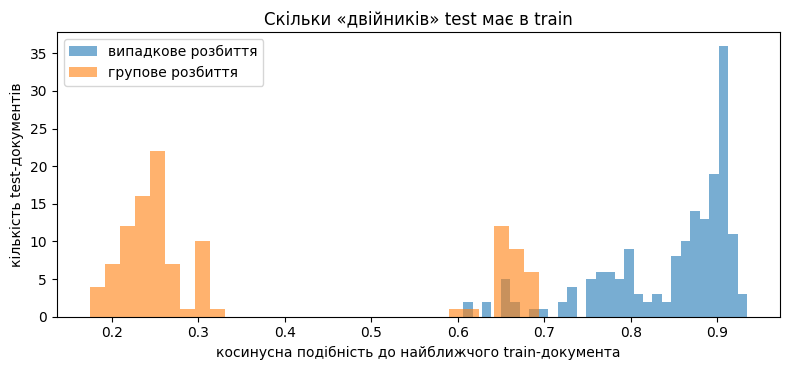

In [39]:
ms_g = max_sim_to(T[idx_te], T[idx_tr])
print("ГРУПОВЕ розбиття (головне): подібність test до найближчого train")
print(f"  медіана = {np.median(ms_g):.2f} | ≥ 0.9: {(ms_g >= 0.9).mean():.1%} | ≥ {NEAR_DUP_THR}: {(ms_g >= NEAR_DUP_THR).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(ms, bins=30, alpha=.6, label="випадкове розбиття"); ax.hist(ms_g, bins=30, alpha=.6, label="групове розбиття")
ax.set_xlabel("косинусна подібність до найближчого train-документа"); ax.set_ylabel("кількість test-документів"); ax.legend(); ax.set_title("Скільки «двійників» test має в train")
plt.tight_layout(); plt.show()

In [40]:
# run_pipeline визначена в розділі 5.1 (той самий код)

res_rand, st_rand, yte_rand = run_pipeline(idx_tr_rand, idx_te_rand)   # випадкове (з витоком)
res_grp,  st_grp,  yte_grp  = run_pipeline(idx_tr, idx_te)             # групове (головне)
cmp9 = res_rand.merge(res_grp, on=["Агрегація", "Класифікатор"], suffixes=(" [випадкове]", " [групове]"))
cmp9["ΔF1 (групове − випадкове)"] = cmp9["F1 (macro) [групове]"] - cmp9["F1 (macro) [випадкове]"]
display(cmp9.set_index(["Агрегація", "Класифікатор"]).round(4))

F1 (macro) [випадкове]  ROC-AUC [випадкове]  Balanced Acc [випадкове]  F1 (macro) [групове]  ROC-AUC [групове]  \
Агрегація            Класифікатор                                                                                                                   
Mean Pooling         SVM                           0.8851               0.9197                    0.8946                0.1679             0.3333   
                     LogReg                        0.7696               0.8467                    0.7736                0.3661             0.3255   
                     KNN                           0.9942               1.0000                    0.9948                0.4657             0.6782   
TF-IDF Weighted Mean SVM                           0.8793               0.9187                    0.8870                0.1679             0.3333   
                     LogReg                        0.7753               0.8598                    0.7788                0.3564             0.3333   
                     KNN                           1.0000               1.0000                    1.0000                0.4657             0.6724   

                                   Balanced Acc [групове]  ΔF1 (групове − випадкове)  
Агрегація            Класифікатор                                                     
Mean Pooling         SVM                           0.5000                    -0.7171  
                     LogReg                        0.6034                    -0.4035  
                     KNN                           0.6667                    -0.5285  
TF-IDF Weighted Mean SVM                           0.5000                    -0.7113  
                     LogReg                        0.5977                    -0.4188  
                     KNN                           0.6667                    -0.5343

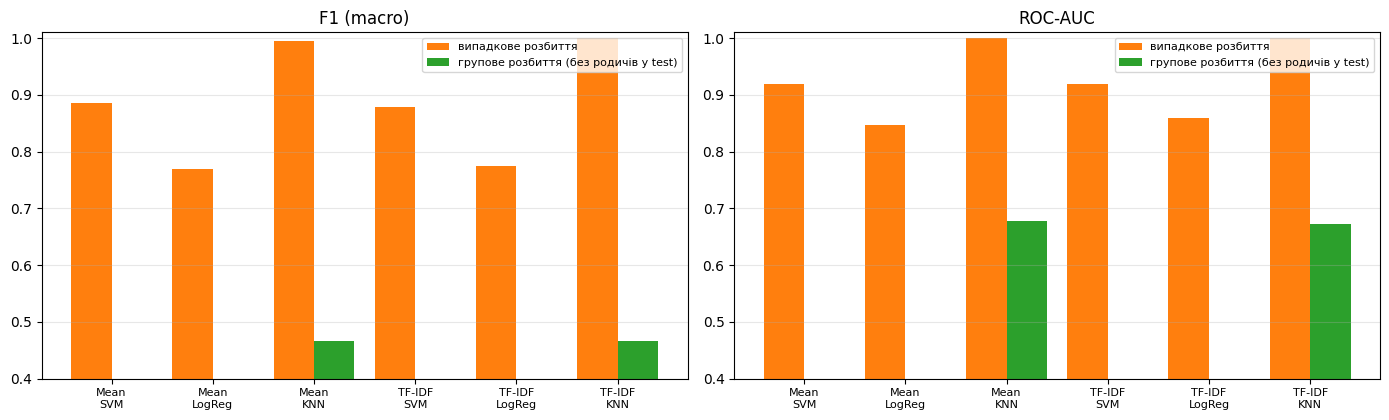

TF-IDF vs Mean Pooling на ГРУПОВОМУ розбитті (без родичів між train і test):


,ΔF1 (TF-IDF − Mean),ΔF1 95% CI,ΔAUC (TF-IDF − Mean),ΔAUC 95% CI
Класифікатор,,,,
SVM,0.0000,"(0.0, 0.0)",0.0000,"(0.0, 0.0)"
LogReg,-0.0097,"(-0.0335, 0.0)",0.0078,"(0.0, 0.0222)"
KNN,0.0000,"(0.0, 0.0)",-0.0057,"(-0.0183, 0.0)"


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
labels = [f"{a.split()[0]}\n{c}" for a, c in zip(cmp9["Агрегація"], cmp9["Класифікатор"])]; xx = np.arange(len(cmp9))
for a, metric in zip(ax, ["F1 (macro)", "ROC-AUC"]):
    a.bar(xx - 0.2, cmp9[f"{metric} [випадкове]"], 0.4, label="випадкове розбиття", color="tab:orange")
    a.bar(xx + 0.2, cmp9[f"{metric} [групове]"], 0.4, label="групове розбиття (без родичів у test)", color="tab:green")
    a.set_xticks(xx); a.set_xticklabels(labels, fontsize=8); a.set_title(metric); a.set_ylim(max(0.4, float(cmp9[[f'{metric} [випадкове]', f'{metric} [групове]']].values.min()) - 0.05), 1.01)
    a.grid(alpha=.3, axis="y"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

def boot_ci(st, yt_, clf, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); n = len(yt_); a, b = st[("Mean Pooling", clf)], st[("TF-IDF Weighted Mean", clf)]; d_f1, d_auc = [], []
    for _ in range(B):
        ix = rng.integers(0, n, n); yy = yt_[ix]
        d_f1.append(f1_score(yy, b["pred"][ix], average="macro") - f1_score(yy, a["pred"][ix], average="macro"))
        d_auc.append(roc_auc_score(yy, b["proba"][ix]) - roc_auc_score(yy, a["proba"][ix]))
    return {"Класифікатор": clf, "ΔF1 (TF-IDF − Mean)": f1_score(yt_, b["pred"], average="macro") - f1_score(yt_, a["pred"], average="macro"),
            "ΔF1 95% CI": tuple(np.percentile(d_f1, [2.5, 97.5]).round(4)),
            "ΔAUC (TF-IDF − Mean)": roc_auc_score(yt_, b["proba"]) - roc_auc_score(yt_, a["proba"]), "ΔAUC 95% CI": tuple(np.percentile(d_auc, [2.5, 97.5]).round(4))}
print("TF-IDF vs Mean Pooling на ГРУПОВОМУ розбитті (без родичів між train і test):")
display(pd.DataFrame([boot_ci(st_grp, yte_grp, c) for c in classifiers]).set_index("Класифікатор").round(4))

### Висновок до Етапу 9

* **Що показано.** Порівняння випадкового розбиття (з витоком, лише для порівняння) з груповим (головним), у якому ніяка «родина» майже-дублікатів не розділена між train і test.
* **Як читати.** Якщо на груповому розбитті метрики **суттєво нижчі** (особливо в KNN), то високі оцінки на випадковому розбитті значною мірою пояснюються **запам'ятовуванням шаблонів**, а не вмінням відрізняти AI від людини: класифікатор бачив у train майже-копії test-текстів. Гістограма вище показує, скільки test-документів мають «двійника» в train за кожного розбиття.
* **Що вважати основним результатом.** Головні результати (Етапи 5–8) тепер отримано саме на **груповому** розбитті; випадкове розбиття наведено лише як «оптимістичну оцінку» з поясненням причини. Через малий обсяг (≈ 60 родин) оцінки на одному груповому test нестабільні, тому додатково виконано 5-fold групову крос-валідацію (розділ 5.1) — її слід вважати остаточним результатом.
* **Обмеження.** Поріг подібності `NEAR_DUP_THR` — евристика; датасет невеликий, тому довірчі інтервали на груповому test широкі.

## Загальний висновок

1. **Дані та обробка.** Датасет проаналізовано (баланс класів, довжини, артефакти: порожні/короткі тексти, дублікати, конфліктні мітки, залежність від довжини), артефакти видалено. Розбиття зроблено **за «родинами» майже-дублікатів** (`StratifiedGroupKFold`, мітки не використовувались) і **до** навчання FastText та обчислення IDF, тому test не бере участі в жодному навчанні, а шаблони не діляться між train і test.
2. **Подання тексту.** Для документів побудовано вектори двома способами (Mean Pooling та TF-IDF Weighted Mean) на основі FastText; FastText дає вектори й для OOV-слів через символьні n-грами.
3. **Класифікація.** Порівняно SVM (RBF), Logistic Regression та KNN за macro-F1, Accuracy, Balanced Accuracy та ROC-AUC; різниця між методами агрегації оцінена з 95% bootstrap-довірчими інтервалами, що дозволяє відрізнити реальний ефект від шуму. Остаточні оцінки отримано 5-fold крос-валідацією за родинами (розділ 5.1) з кластерним bootstrap. Додатково (Етап 9) показано, наскільки випадкове розбиття завищує оцінки через витік майже-дублікатів.
4. **Гіпотеза.** Підтверджується вона чи ні, визначає автоматичний вердикт (Етап 8) та геометрія (таблиця 6.2): TF-IDF змінює геометрію (розсіювання документів, ефективну розмірність, роздільність центроїдів), але це перетворюється на вищу якість лише тоді, коли сигнал про клас міститься саме в рідкісних термінах.
5. **KNN** найчутливіший до зміни метричних властивостей простору (концентрація відстаней, шум рідкісних слів), а SVM/LogReg краще справляються, бо вчать ваги напрямків.
6. **Обмеження:** використано підвибірку (`MAX_DOCS`), параметри моделей за замовчуванням (без підбору), невелика кількість родин (≈ 60), через що навіть 5-fold оцінки мають помітний розкид; видалення стоп-слів та пунктуації прибирає стилометричні ознаки; артефакти датасету (довжина, домен, моделі-генератори) можуть пояснювати частину якості. Для надійнішого висновку потрібен більший і різноманітніший датасет (різні шаблони/моделі-генератори, реальні тексти людей).